In [1]:
import os
print(os.getcwd())  

...\projet_nlp\notebooks


In [2]:
import pandas as pd

GROUPES = ["cs", "math", "physics", "q-bio", "q-fin", "stat", "eess", "econ"]

# ".." = on remonte d'un dossier, car le notebook est dans notebooks/
df = pd.read_csv("../data/raw/arxiv_echantillon.csv", dtype={"id": str})

print("Taille :", df.shape)
df.head()

Taille : (19982, 11)


,id,title,abstract,cs,math,physics,q-bio,q-fin,stat,eess,econ
0,0704.0125,Anisotropic thermo-elasticity in 2D -- Part I:...,In this note we develop tools and techniques...,0,1,0,0,0,0,0,0
1,0704.0291,Approaching the Heisenberg limit in an atom laser,We present experimental and theoretical resu...,0,0,1,0,0,0,0,0
2,0704.0369,"The effect of Topcolor Assisted Technicolor, a...",New physics beyond the Standard Model can le...,0,0,1,0,0,0,0,0
3,0704.0395,A Study of $B_{d}^0 \to J/\Psi \eta^{(\prime)}...,Motivated by the very recent measurement of ...,0,0,1,0,0,0,0,0
4,0704.0428,Star Formation in the Bok Globule CB54,"We present mid-infrared (10.4 \micron, 11.7 ...",0,0,1,0,0,0,0,0


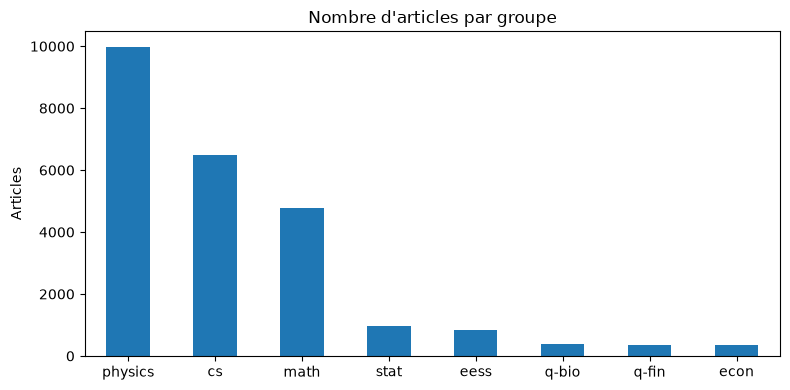

In [3]:
import matplotlib.pyplot as plt

# Somme de chaque colonne = nombre d'articles dans chaque groupe
compte = df[GROUPES].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
compte.plot(kind="bar")
plt.title("Nombre d'articles par groupe")
plt.ylabel("Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../results/repartition_groupes.png", dpi=150)  # image gardée pour le README
plt.show()

1    16379
2     3075
3      474
4       53
5        1
Name: count, dtype: int64
Moyenne : 1.21 groupe(s) par article


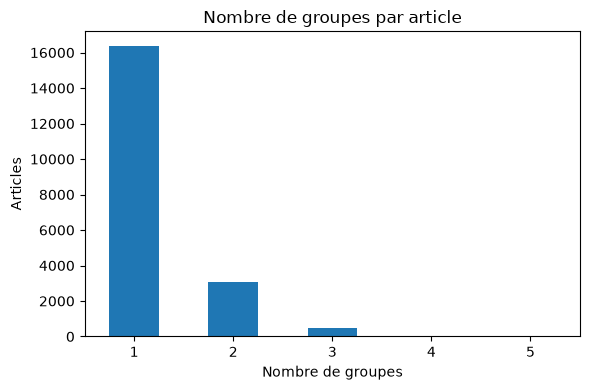

In [4]:
# Pour chaque article (chaque ligne) : combien de 1 sur sa ligne ?
nb_groupes = df[GROUPES].sum(axis=1)

repartition = nb_groupes.value_counts().sort_index()
print(repartition)
print("Moyenne :", round(nb_groupes.mean(), 2), "groupe(s) par article")

plt.figure(figsize=(6, 4))
repartition.plot(kind="bar")
plt.title("Nombre de groupes par article")
plt.xlabel("Nombre de groupes")
plt.ylabel("Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../results/nb_groupes_par_article.png", dpi=150)
plt.show()

           cs  math  physics  q-bio  q-fin  stat  eess  econ
cs       6488  1040      382    103     78   498   686    81
math     1040  4780      764     49     64   249   139    35
physics   382   764     9982    123     51    61    48    21
q-bio     103    49      123    391      3    32    15     2
q-fin      78    64       51      3    368    41     3   165
stat      498   249       61     32     41   977    27    61
eess      686   139       48     15      3    27   835     4
econ       81    35       21      2    165    61     4   347


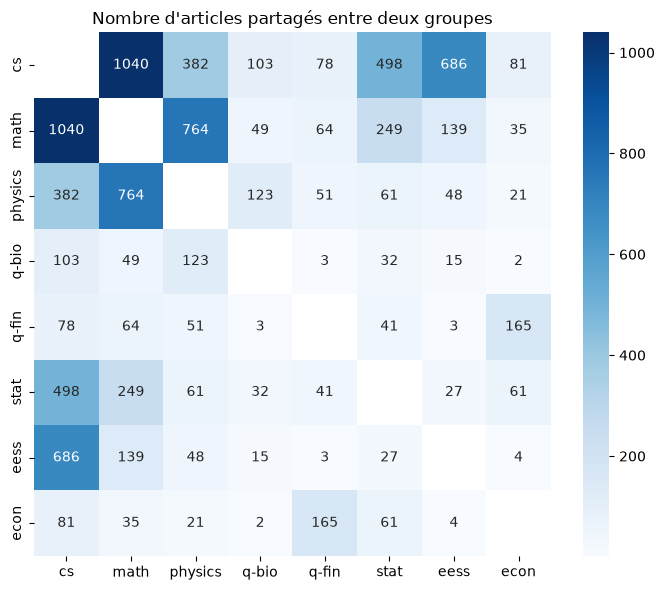

In [5]:
import numpy as np
import seaborn as sns

# Tableau 8 x 8 rempli de 0
cooc = pd.DataFrame(0, index=GROUPES, columns=GROUPES)

# Pour chaque paire (a, b) : nombre d'articles qui ont a = 1 ET b = 1
for a in GROUPES:
    for b in GROUPES:
        cooc.loc[a, b] = ((df[a] == 1) & (df[b] == 1)).sum()

print(cooc)

# On cache la diagonale (cs avec cs = taille du groupe, déjà vue dans le 1er graphique)
masque = np.eye(len(GROUPES), dtype=bool)

plt.figure(figsize=(7, 6))
sns.heatmap(cooc, mask=masque, annot=True, fmt="d", cmap="Blues")
plt.title("Nombre d'articles partagés entre deux groupes")
plt.tight_layout()
plt.savefig("../results/cooccurrence_groupes.png", dpi=150)
plt.show()

count    19982.000000
mean       222.944900
std         93.808935
min         41.000000
25%        153.000000
50%        213.000000
75%        281.000000
max        960.000000
Name: nb_tokens, dtype: float64

Résumés de plus de 256 tokens : 33.5 %
Résumés de plus de 320 tokens : 14.8 %
Résumés de plus de 384 tokens : 5.2 %
Résumés de plus de 512 tokens : 0.7 %


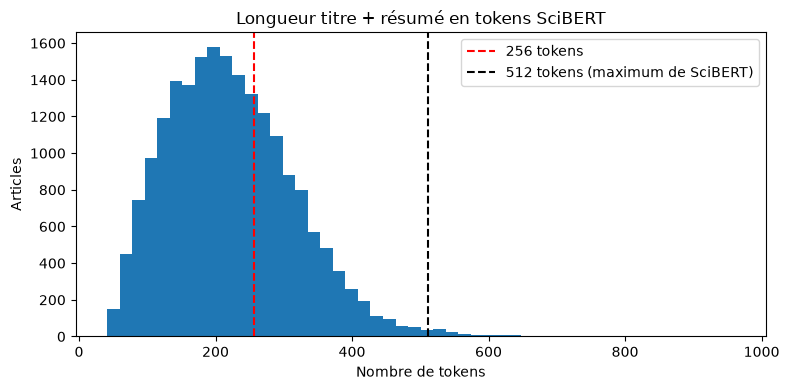

In [6]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("allenai/scibert_scivocab_uncased")

# On tokenise tous les résumés d'un coup ; input_ids = la liste des tokens de chaque résumé
encodages = tokenizer(df["title"].tolist(), df["abstract"].tolist())   # titre + résumé
df["nb_tokens"] = [len(ids) for ids in encodages["input_ids"]]

print(df["nb_tokens"].describe())
print()
for limite in [256, 320, 384, 512]:
    pct = 100 * (df["nb_tokens"] > limite).mean()
    print(f"Résumés de plus de {limite} tokens : {pct:.1f} %")

plt.figure(figsize=(8, 4))
plt.hist(df["nb_tokens"], bins=50)
plt.axvline(256, color="red", linestyle="--", label="256 tokens")
plt.axvline(512, color="black", linestyle="--", label="512 tokens (maximum de SciBERT)")
plt.title("Longueur titre + résumé en tokens SciBERT")
plt.xlabel("Nombre de tokens")
plt.ylabel("Articles")
plt.legend()
plt.tight_layout()
plt.savefig("../results/longueur_resumes.png", dpi=150)
plt.show()

## Conclusions de l'exploration (version 2 : échantillon proportionnel)

- **Données** : 19 982 articles arXiv (titre + résumé), 8 groupes. Tirage proportionnel à la vraie répartition d'arXiv (taux 0,61 %), avec un minimum d'environ 300 articles pour q-fin et econ.
- **Répartition** : très déséquilibrée. physics 9 982 (50 %), cs 6 488 (32,5 %), math 4 780 (23,9 %), puis stat 977, eess 835, q-bio 391, q-fin 368, econ 347. Rapport ×29 entre physics et econ.
- **Multi-label** : 82 % des articles ont un seul groupe, 15,4 % en ont 2, 2,6 % en ont 3 ou plus. Moyenne : 1,21 groupe par article (1,66 dans la version 1 rééquilibrée).
- **Co-occurrences** : cs+math (1 040), math+physics (764), cs+eess (686, soit 82 % des articles eess), cs+stat (498, soit 51 % des articles stat), q-fin+econ (165, environ la moitié de chacun).
- **Conséquences attendues** : physics, cs et math portent 88 % des labels, donc le micro-F1 dépendra surtout d'eux et sera plus élevé que dans la version 1. Les petits groupes seront plus difficiles, donc le macro-F1 sera plus bas. Avec seulement 52 à 59 articles par petit groupe dans le test, leur score sera instable.
- **Longueur (titre + résumé)** : médiane de 213 tokens SciBERT. Avec `max_length = 384`, 94,8 % des textes sont lus en entier ; avec 512, 99,3 %. On garde 384 au départ et on testera 512 pendant l'optimisation.